# Olist Brazilian E-Commerce — EDA & Preprocessing

**Pipeline position:** step 1 of a local BI portfolio project.

```
Kaggle (this notebook) --> cleaned CSVs --> SSIS (staging) --> SQL Server DW (star schema)
                                        --> SSAS Tabular --> Power BI / Report Builder
```

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
— ~100k orders (2016–2018) across 9 relational tables.

**Structure of this notebook**

- **Part A — Exploratory Data Analysis (read-only).** Profile every table,
  measure data-quality issues, check referential integrity, compute headline
  KPIs. Nothing is modified; every finding is quantified.
- **Part B — Preprocessing.** Apply the cleaning rules justified by Part A,
  each one printing the number of rows it affects, then export SSIS-ready CSVs
  to `/kaggle/working/clean/` (download from the notebook's Output tab).

**Outputs**

| File | Grain |
|---|---|
| `orders_clean.csv` | 1 row per order |
| `order_items_clean.csv` | 1 row per order line |
| `customers_clean.csv` | 1 row per order-customer key |
| `sellers_clean.csv` | 1 row per seller |
| `products_clean.csv` | 1 row per product (with English category) |
| `payments_clean.csv` | 1 row per payment record |
| `reviews_clean.csv` | 1 row per (review, order) |
| `geolocation_clean.csv` | 1 row per zip-code prefix |

## Setup and load

In [3]:
import os, glob
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

# Auto-detect the dataset wherever Kaggle mounted it under /kaggle/input
hits = glob.glob('/kaggle/input/**/olist_orders_dataset.csv', recursive=True)
assert hits, 'Olist files not found — attach the brazilian-ecommerce dataset to this notebook.'
IN_DIR = os.path.dirname(hits[0])
OUT_DIR = '/kaggle/working/clean'
os.makedirs(OUT_DIR, exist_ok=True)
print('input :', IN_DIR)
print('output:', OUT_DIR)

input : /kaggle/input/datasets/olistbr/brazilian-ecommerce
output: /kaggle/working/clean


In [4]:
# Zip-code prefixes have leading zeros -> must be read as strings, never integers.
customers   = pd.read_csv(f'{IN_DIR}/olist_customers_dataset.csv',
                          dtype={'customer_zip_code_prefix': str})
geolocation = pd.read_csv(f'{IN_DIR}/olist_geolocation_dataset.csv',
                          dtype={'geolocation_zip_code_prefix': str})
order_items = pd.read_csv(f'{IN_DIR}/olist_order_items_dataset.csv')
payments    = pd.read_csv(f'{IN_DIR}/olist_order_payments_dataset.csv')
reviews     = pd.read_csv(f'{IN_DIR}/olist_order_reviews_dataset.csv')
orders      = pd.read_csv(f'{IN_DIR}/olist_orders_dataset.csv')
products    = pd.read_csv(f'{IN_DIR}/olist_products_dataset.csv')
sellers     = pd.read_csv(f'{IN_DIR}/olist_sellers_dataset.csv',
                          dtype={'seller_zip_code_prefix': str})
translation = pd.read_csv(f'{IN_DIR}/product_category_name_translation.csv')

tables = {'orders': orders, 'order_items': order_items, 'customers': customers,
          'sellers': sellers, 'products': products, 'payments': payments,
          'reviews': reviews, 'geolocation': geolocation, 'translation': translation}

for name, df in tables.items():
    print(f'{name:<12} {df.shape[0]:>10,} rows  x {df.shape[1]:>2} cols')

orders           99,441 rows  x  8 cols
order_items     112,650 rows  x  7 cols
customers        99,441 rows  x  5 cols
sellers           3,095 rows  x  4 cols
products         32,951 rows  x  9 cols
payments        103,886 rows  x  5 cols
reviews          99,224 rows  x  7 cols
geolocation   1,000,163 rows  x  5 cols
translation          71 rows  x  2 cols


---
# Part A — Exploratory Data Analysis

Read-only: this part measures and documents; it changes nothing. Every
cleaning rule applied in Part B is justified by a number printed here.

## A.1 Missing values, duplicates, and key uniqueness

In [5]:
# --- Missing values per column (only columns that have any) ---
rows = []
for name, df in tables.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            rows.append((name, col, n, f'{n/len(df):.2%}'))
missing = pd.DataFrame(rows, columns=['table', 'column', 'missing', 'pct'])
missing.sort_values('missing', ascending=False)

,table,column,missing,pct
11,reviews,review_comment_title,87656,88.34%
12,reviews,review_comment_message,58247,58.70%
2,orders,order_delivered_customer_date,2965,2.98%
1,orders,order_delivered_carrier_date,1783,1.79%
3,products,product_category_name,610,1.85%
5,products,product_description_lenght,610,1.85%
4,products,product_name_lenght,610,1.85%
6,products,product_photos_qty,610,1.85%
0,orders,order_approved_at,160,0.16%
8,products,product_length_cm,2,0.01%


In [6]:
# --- Full-row duplicates ---
for name, df in tables.items():
    d = int(df.duplicated().sum())
    print(f'{name:<12} full-row duplicates: {d:>8,}')

orders       full-row duplicates:        0
order_items  full-row duplicates:        0
customers    full-row duplicates:        0
sellers      full-row duplicates:        0
products     full-row duplicates:        0
payments     full-row duplicates:        0
reviews      full-row duplicates:        0
geolocation  full-row duplicates:  261,831
translation  full-row duplicates:        0


In [7]:
# --- Expected-key uniqueness ---
checks = [
    ('orders',      'order_id',       orders['order_id']),
    ('customers',   'customer_id',    customers['customer_id']),
    ('sellers',     'seller_id',      sellers['seller_id']),
    ('products',    'product_id',     products['product_id']),
    ('order_items', 'order_id+item',  order_items[['order_id', 'order_item_id']]
                                        .astype(str).agg('-'.join, axis=1)),
    ('reviews',     'review_id',      reviews['review_id']),
    ('reviews',     'review+order',   reviews[['review_id', 'order_id']]
                                        .astype(str).agg('-'.join, axis=1)),
]
for table, key, series in checks:
    dup = int(series.duplicated().sum())
    status = 'UNIQUE' if dup == 0 else f'{dup:,} duplicates'
    print(f'{table:<12} key {key:<14} -> {status}')

orders       key order_id       -> UNIQUE
customers    key customer_id    -> UNIQUE
sellers      key seller_id      -> UNIQUE
products     key product_id     -> UNIQUE
order_items  key order_id+item  -> UNIQUE
reviews      key review_id      -> 814 duplicates
reviews      key review+order   -> UNIQUE


**Reading the results** (verify against the printed output above — the numbers
printed by *your* run are the source of truth):

- `orders`: delivery-related timestamps are missing for orders that were never
  delivered — structural, not an error (confirmed in A.2).
- `reviews`: comment title/message are mostly empty, and `review_id` is **not**
  unique — one review can be attached to several orders.
- `products`: a block of products has no category and no descriptive attributes.
- `geolocation`: massive full-row duplication — one row per observation, not
  per zip prefix.

## A.2 Orders: dates, statuses, timeline consistency

Dates are parsed here (with failure counts) because every analysis below needs
them; parsing is a type conversion, not a cleaning decision.

In [8]:
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

for c in date_cols:
    raw_non_null = orders[c].notna().sum()
    orders[c] = pd.to_datetime(orders[c], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    failed = raw_non_null - orders[c].notna().sum()
    print(f'{c:<34} parse failures: {failed}')

print('\nOrder date range:', orders['order_purchase_timestamp'].min(),
      '->', orders['order_purchase_timestamp'].max())
orders['order_status'].value_counts()

order_purchase_timestamp           parse failures: 0
order_approved_at                  parse failures: 0
order_delivered_carrier_date       parse failures: 0
order_delivered_customer_date      parse failures: 0
order_estimated_delivery_date      parse failures: 0

Order date range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [9]:
# Structural missingness: share of orders with a delivered-to-customer date, by status
pd.crosstab(orders['order_status'],
            orders['order_delivered_customer_date'].notna(),
            normalize='index').round(3).rename(columns={False: 'missing', True: 'present'})

order_delivered_customer_date,missing,present
order_status,,
approved,1.00,0.00
canceled,0.99,0.01
created,1.00,0.00
delivered,0.00,1.00
invoiced,1.00,0.00
processing,1.00,0.00
shipped,1.00,0.00
unavailable,1.00,0.00


In [10]:
# Timeline anomalies: delivered before purchased, or shipped before approval
mask_delivery = (orders['order_delivered_customer_date'].notna()
                 & (orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']))
mask_carrier  = (orders['order_delivered_carrier_date'].notna()
                 & orders['order_approved_at'].notna()
                 & (orders['order_delivered_carrier_date'] < orders['order_approved_at']))

print(f'delivered before purchase : {int(mask_delivery.sum()):,}')
print(f'shipped before approval   : {int(mask_carrier.sum()):,}')

delivered before purchase : 0
shipped before approval   : 1,359


Text(0, 0.5, 'orders')

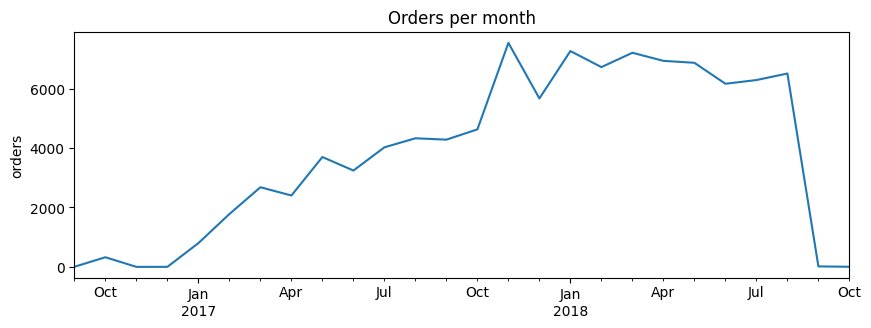

In [11]:
# Monthly order volume — the shape every Olist dashboard must reproduce
monthly = (orders.set_index('order_purchase_timestamp')
           .resample('MS')['order_id'].count())
ax = monthly.plot(figsize=(10, 3.2), title='Orders per month')
ax.set_xlabel(''); ax.set_ylabel('orders')

## A.3 Customers and sellers

`customer_id` is an **order-scoped** key (one per order); `customer_unique_id`
identifies the person. The DW customer dimension will be keyed on
`customer_unique_id`, while `customer_id` joins to `orders`.

In [12]:
n_people = customers['customer_unique_id'].nunique()
print(f'order-customer keys : {len(customers):,}')
print(f'unique persons      : {n_people:,}')
print(f'repeat buyers       : {len(customers) - n_people:,} extra order-keys')
print(f'\nzip prefix lengths  : {sorted(customers["customer_zip_code_prefix"].str.len().unique())}'
      '  (any value < 5 means leading zeros were lost upstream and must be re-padded)')
print(f'\nsellers             : {len(sellers):,} | states: {sellers["seller_state"].nunique()}')
customers['customer_state'].value_counts().head(10)

order-customer keys : 99,441
unique persons      : 96,096
repeat buyers       : 3,345 extra order-keys

zip prefix lengths  : [np.int64(5)]  (any value < 5 means leading zeros were lost upstream and must be re-padded)

sellers             : 3,095 | states: 23


customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

## A.4 Order items and payments

In [13]:
print(order_items[['price', 'freight_value']].describe().round(2))
print(f"\nprice <= 0        : {int((order_items['price'] <= 0).sum()):,}")
print(f"freight_value < 0 : {int((order_items['freight_value'] < 0).sum()):,}")
print(f"freight_value = 0 : {int((order_items['freight_value'] == 0).sum()):,}  (possible free shipping)")

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68

price <= 0        : 0
freight_value < 0 : 0
freight_value = 0 : 383  (possible free shipping)


In [14]:
print(payments['payment_type'].value_counts())
print(f"\ninstallments = 0  : {int((payments['payment_installments'] == 0).sum()):,}")
print(f"payment_value = 0 : {int((payments['payment_value'] == 0).sum()):,}")

# Reconciliation: payment total vs items total per order
pay_tot  = payments.groupby('order_id')['payment_value'].sum()
item_tot = (order_items.assign(total=order_items['price'] + order_items['freight_value'])
            .groupby('order_id')['total'].sum())
recon = pd.concat([pay_tot, item_tot], axis=1, keys=['paid', 'items']).dropna()
recon['diff'] = (recon['paid'] - recon['items']).round(2)
within_1 = (recon['diff'].abs() <= 1.0).mean()
print(f'\norders where |paid - items| <= R$1: {within_1:.1%} of {len(recon):,} matched orders')

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

installments = 0  : 2
payment_value = 0 : 9

orders where |paid - items| <= R$1: 99.7% of 98,665 matched orders


## A.5 Reviews

In [15]:
dup_exact = int(reviews.duplicated().sum())
dup_pair  = int(reviews.duplicated(subset=['review_id', 'order_id']).sum())
with_text = int(reviews['review_comment_message'].notna().sum())
has_break = int(reviews['review_comment_message'].astype('string')
                .str.contains(r'[\r\n]', regex=True, na=False).sum())
print(f'exact duplicate rows            : {dup_exact:,}')
print(f'duplicate (review_id, order_id) : {dup_pair:,}')
print(f'reviews with a text comment     : {with_text:,} ({with_text/len(reviews):.1%})')
print(f'comments containing line breaks : {has_break:,}  (breaks flat-file parsing -> fixed in Part B)')
reviews['review_score'].value_counts().sort_index()

exact duplicate rows            : 0
duplicate (review_id, order_id) : 0
reviews with a text comment     : 40,977 (41.3%)
comments containing line breaks : 3,852  (breaks flat-file parsing -> fixed in Part B)


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

## A.6 Products and category translation

In [16]:
no_cat = int(products['product_category_name'].isna().sum())
print(f'products without category: {no_cat:,}')
print(f'distinct categories (pt) : {products["product_category_name"].nunique()}')

cats_in_products = set(products['product_category_name'].dropna().unique())
cats_translated  = set(translation['product_category_name'])
untranslated = sorted(cats_in_products - cats_translated)
print(f'categories missing from translation file: {untranslated}')

# Note the misspelled source columns -> renamed in Part B
print('\nsource columns:', [c for c in products.columns if 'lenght' in c])

products without category: 610
distinct categories (pt) : 73
categories missing from translation file: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

source columns: ['product_name_lenght', 'product_description_lenght']


## A.7 Geolocation

In [17]:
n_prefix = geolocation['geolocation_zip_code_prefix'].nunique()
print(f'rows                : {len(geolocation):,}')
print(f'unique zip prefixes : {n_prefix:,}  ->  avg {len(geolocation)/n_prefix:.0f} rows per prefix')

outside = ~(geolocation['geolocation_lat'].between(-35, 6)
            & geolocation['geolocation_lng'].between(-75, -33))
print(f'coordinates outside Brazil bounding box (lat -35..6, lng -75..-33): {int(outside.sum()):,}')

rows                : 1,000,163
unique zip prefixes : 19,015  ->  avg 53 rows per prefix
coordinates outside Brazil bounding box (lat -35..6, lng -75..-33): 40


## A.8 Referential integrity

The star-schema load depends on these relationships. Any gap must be handled in
SSIS (lookup with no-match redirect) — so we measure them now. Zip prefixes are
padded on the fly for a fair comparison.

In [18]:
def ri(child_name, child_keys, parent_name, parent_keys):
    orphans = int((~child_keys.isin(set(parent_keys))).sum())
    pct = orphans / max(len(child_keys), 1)
    print(f'{child_name:<28} -> {parent_name:<22} orphans: {orphans:>7,} ({pct:.3%})')

geo_prefixes = geolocation['geolocation_zip_code_prefix'].str.zfill(5)
ri('orders.customer_id',      orders['customer_id'],      'customers.customer_id', customers['customer_id'])
ri('order_items.order_id',    order_items['order_id'],    'orders.order_id',       orders['order_id'])
ri('order_items.product_id',  order_items['product_id'],  'products.product_id',   products['product_id'])
ri('order_items.seller_id',   order_items['seller_id'],   'sellers.seller_id',     sellers['seller_id'])
ri('payments.order_id',       payments['order_id'],       'orders.order_id',       orders['order_id'])
ri('reviews.order_id',        reviews['order_id'],        'orders.order_id',       orders['order_id'])
ri('customers.zip_prefix',    customers['customer_zip_code_prefix'].str.zfill(5),
   'geolocation.zip_prefix',  geo_prefixes)
ri('sellers.zip_prefix',      sellers['seller_zip_code_prefix'].str.zfill(5),
   'geolocation.zip_prefix',  geo_prefixes)

orders.customer_id           -> customers.customer_id  orphans:       0 (0.000%)
order_items.order_id         -> orders.order_id        orphans:       0 (0.000%)
order_items.product_id       -> products.product_id    orphans:       0 (0.000%)
order_items.seller_id        -> sellers.seller_id      orphans:       0 (0.000%)
payments.order_id            -> orders.order_id        orphans:       0 (0.000%)
reviews.order_id             -> orders.order_id        orphans:       0 (0.000%)
customers.zip_prefix         -> geolocation.zip_prefix orphans:     278 (0.280%)
sellers.zip_prefix           -> geolocation.zip_prefix orphans:       7 (0.226%)


## A.9 Headline KPIs

Reference figures for the README — the dashboard built later must reproduce
these numbers.

In [19]:
delivered = orders[orders['order_status'] == 'delivered']
merged = order_items.merge(delivered[['order_id']], on='order_id', how='inner')

gmv = (merged['price'] + merged['freight_value']).sum()
aov = (merged.assign(order_total=merged['price'] + merged['freight_value'])
       .groupby('order_id')['order_total'].sum().mean())
delay = (delivered['order_delivered_customer_date']
         - delivered['order_purchase_timestamp']).dt.days
late = (delivered['order_delivered_customer_date']
        > delivered['order_estimated_delivery_date']).mean()

print(f'delivered orders            : {len(delivered):,}')
print(f'GMV (price + freight)       : R$ {gmv:,.0f}')
print(f'average order value         : R$ {aov:,.2f}')
print(f'median delivery time        : {delay.median():.0f} days')
print(f'late deliveries             : {late:.1%}')
print(f'average review score        : {reviews["review_score"].mean():.2f}')

delivered orders            : 96,478
GMV (price + freight)       : R$ 15,419,774
average order value         : R$ 159.83
median delivery time        : 10 days
late deliveries             : 8.1%
average review score        : 4.09


## A.10 EDA conclusions → cleaning rules

| # | Finding (Part A) | Rule applied in Part B |
|---|---|---|
| 1 | Timeline anomalies exist (A.2) | Flag with `has_timeline_anomaly`; keep rows |
| 2 | Zip prefixes are strings with leading zeros (A.3) | Pad to 5 digits everywhere |
| 3 | City/state casing inconsistent (A.3) | Trim; city lowercase, state uppercase |
| 4 | Duplicate reviews + line breaks in comments (A.5) | Dedupe to `(review_id, order_id)`; strip breaks |
| 5 | Misspelled columns, missing/untranslated categories (A.6) | Rename `lenght`→`length`; join English names with documented fallbacks |
| 6 | Geolocation duplicated per observation, outliers outside Brazil (A.7) | Filter bounding box; aggregate to one row per prefix (median lat/lng, mode city/state) |
| 7 | Some customer/seller zips missing from geolocation (A.8) | DW geography dimension needs an *Unknown* member; SSIS lookup redirects no-match rows |
| 8 | `installments = 0` and multi-payment orders (A.4) | Keep as-is (real system records); DW load decides |

---
# Part B — Preprocessing

Applies rules 1–6 from A.10. Every transformation prints the number of rows it
affects.

## B.1 Orders — anomaly flag

In [20]:
orders['has_timeline_anomaly'] = (mask_delivery | mask_carrier).astype(int)
print(f'rows flagged (kept): {int(orders["has_timeline_anomaly"].sum()):,}')

rows flagged (kept): 1,359


## B.2 Customers and sellers — zip padding, text normalization

In [21]:
customers['customer_zip_code_prefix'] = customers['customer_zip_code_prefix'].str.zfill(5)
customers['customer_city'] = customers['customer_city'].str.strip().str.lower()
customers['customer_state'] = customers['customer_state'].str.strip().str.upper()

sellers['seller_zip_code_prefix'] = sellers['seller_zip_code_prefix'].str.zfill(5)
sellers['seller_city'] = sellers['seller_city'].str.strip().str.lower()
sellers['seller_state'] = sellers['seller_state'].str.strip().str.upper()
print('customers and sellers normalized')

customers and sellers normalized


## B.3 Order items — date parsing

In [22]:
raw_non_null = order_items['shipping_limit_date'].notna().sum()
order_items['shipping_limit_date'] = pd.to_datetime(
    order_items['shipping_limit_date'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
print(f'shipping_limit_date parse failures: {raw_non_null - order_items["shipping_limit_date"].notna().sum()}')

shipping_limit_date parse failures: 0


## B.4 Reviews — dedupe, strip line breaks, parse dates

In [23]:
before = len(reviews)
reviews = reviews.drop_duplicates()
reviews = reviews.drop_duplicates(subset=['review_id', 'order_id'], keep='first')
print(f'rows removed as duplicates: {before - len(reviews):,}')

for c in ['review_comment_title', 'review_comment_message']:
    reviews[c] = (reviews[c]
                  .astype('string')                      # safe even if the column is all-NaN
                  .str.replace(r'[\r\n]+', ' ', regex=True)
                  .str.strip())

for c in ['review_creation_date', 'review_answer_timestamp']:
    raw_non_null = reviews[c].notna().sum()
    reviews[c] = pd.to_datetime(reviews[c], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    print(f'{c:<26} parse failures: {raw_non_null - reviews[c].notna().sum()}')

rows removed as duplicates: 0
review_creation_date       parse failures: 0
review_answer_timestamp    parse failures: 0


## B.5 Products — rename columns, join English categories

In [24]:
products = products.rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'})

products = products.merge(translation, on='product_category_name', how='left')

n_fallback_pt = int((products['product_category_name'].notna()
                     & products['product_category_name_english'].isna()).sum())
n_unknown = int(products['product_category_name'].isna().sum())

products['product_category_name_english'] = (
    products['product_category_name_english']
    .fillna(products['product_category_name'])   # fallback: Portuguese name
    .fillna('unknown'))                           # no category at all
products['product_category_name'] = products['product_category_name'].fillna('unknown')

print(f'products using Portuguese fallback name : {n_fallback_pt:,}')
print(f"products set to 'unknown' category      : {n_unknown:,}")
print(f"distinct categories (english)           : {products['product_category_name_english'].nunique()}")

products using Portuguese fallback name : 13
products set to 'unknown' category      : 610
distinct categories (english)           : 74


## B.6 Geolocation — filter outliers, one row per zip prefix

In [25]:
geolocation['geolocation_zip_code_prefix'] = geolocation['geolocation_zip_code_prefix'].str.zfill(5)
geolocation['geolocation_city'] = geolocation['geolocation_city'].str.strip().str.lower()
geolocation['geolocation_state'] = geolocation['geolocation_state'].str.strip().str.upper()

in_brazil = (geolocation['geolocation_lat'].between(-35, 6)
             & geolocation['geolocation_lng'].between(-75, -33))
print(f'coordinates outside Brazil bounding box (removed): {int((~in_brazil).sum()):,}')
geo = geolocation[in_brazil]

def mode_first(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

geolocation_clean = (geo.groupby('geolocation_zip_code_prefix')
    .agg(geolocation_lat=('geolocation_lat', 'median'),
         geolocation_lng=('geolocation_lng', 'median'),
         geolocation_city=('geolocation_city', mode_first),
         geolocation_state=('geolocation_state', mode_first))
    .reset_index())

print(f'{len(geolocation):,} raw rows -> {len(geolocation_clean):,} unique zip prefixes')

coordinates outside Brazil bounding box (removed): 40
1,000,163 raw rows -> 19,010 unique zip prefixes


## B.7 Export SSIS-ready files

Format contract for the SSIS flat-file connection managers:

| Setting | Value |
|---|---|
| Encoding / code page | UTF-8 (**65001**) |
| Delimiter | comma |
| Text qualifier | `"` |
| Header row | yes |
| Date format | `yyyy-MM-dd HH:mm:ss` |
| NULL representation | empty field |
| Embedded line breaks | none (removed in B.4) |

In [26]:
EXPORTS = {
    'orders_clean.csv':      orders,
    'order_items_clean.csv': order_items,
    'customers_clean.csv':   customers,
    'sellers_clean.csv':     sellers,
    'products_clean.csv':    products,
    'payments_clean.csv':    payments,
    'reviews_clean.csv':     reviews,
    'geolocation_clean.csv': geolocation_clean,
}

for fname, df in EXPORTS.items():
    path = f'{OUT_DIR}/{fname}'
    df.to_csv(path, index=False, encoding='utf-8',
              date_format='%Y-%m-%d %H:%M:%S')
    print(f'{fname:<26} {len(df):>9,} rows  {os.path.getsize(path)/1e6:>7.1f} MB')

orders_clean.csv              99,441 rows     17.6 MB
order_items_clean.csv        112,650 rows     14.9 MB
customers_clean.csv           99,441 rows      8.6 MB
sellers_clean.csv              3,095 rows      0.2 MB
products_clean.csv            32,951 rows      3.3 MB
payments_clean.csv           103,886 rows      5.6 MB
reviews_clean.csv             99,224 rows     13.9 MB
geolocation_clean.csv         19,010 rows      1.1 MB


In [27]:
# Verification: every exported file reloads with identical shape and no parser errors
for fname, df in EXPORTS.items():
    back = pd.read_csv(f'{OUT_DIR}/{fname}', dtype=str, keep_default_na=False)
    assert back.shape == (len(df), df.shape[1]), f'{fname}: shape mismatch {back.shape}'
    print(f'{fname:<26} reload OK  {back.shape}')
print('\nAll exports verified.')

orders_clean.csv           reload OK  (99441, 9)
order_items_clean.csv      reload OK  (112650, 7)
customers_clean.csv        reload OK  (99441, 5)
sellers_clean.csv          reload OK  (3095, 4)
products_clean.csv         reload OK  (32951, 10)
payments_clean.csv         reload OK  (103886, 5)
reviews_clean.csv          reload OK  (99224, 7)
geolocation_clean.csv      reload OK  (19010, 5)

All exports verified.


## Next step

Download the `clean/` folder from this notebook's **Output** tab and place the
files in `C:\BI-Portfolio\data\clean\`. The SSIS staging packages read them
with the flat-file settings from B.7.

Carry-over decisions for the warehouse design:
- Customer dimension keyed on `customer_unique_id`; `customer_id` is the join to orders.
- Geography dimension needs an **Unknown** member (unmatched zip prefixes, A.8).
- `has_timeline_anomaly` lets the fact load exclude or flag inconsistent orders.
- Review grain is `(review_id, order_id)`; payments grain is `(order_id, payment_sequential)`.